# Czym jest sygnał?

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests

rng = np.random.default_rng(2137)

plt.rcParams["font.size"] = 12

sampling_frequency = 500
duration = 2

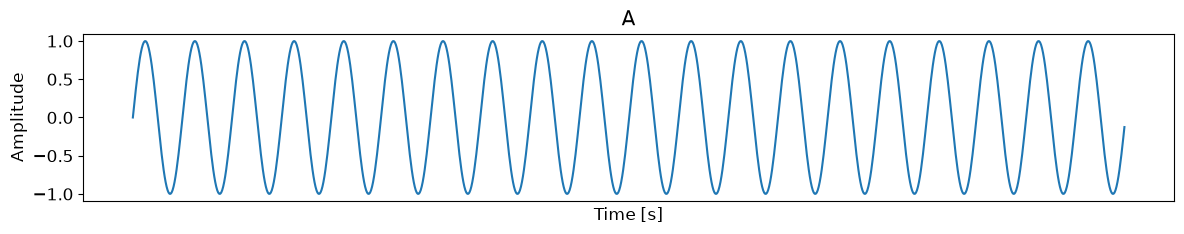

In [50]:
# A
t = np.arange(0, duration, 1/sampling_frequency)

A = np.sin(2 * np.pi * 10 * t)

plt.figure(figsize=(12, 2.5))
plt.plot(t, A)

plt.title("A")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.tight_layout()
plt.show()

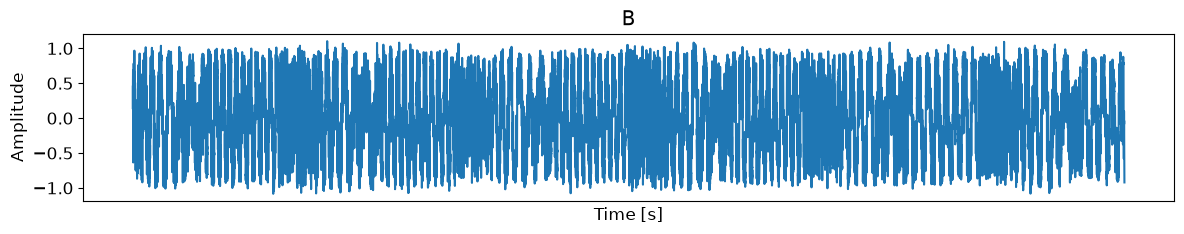

In [51]:
# B
import librosa

y, sr = librosa.load("ANGUISH, Lieless  - far away.mp3", sr=None)

start_sec = 30

start = int(start_sec * sr)
stop = int((start_sec + duration) * sr)

music = y[start:stop]

t_music = np.arange(len(music)) / sr

plt.figure(figsize=(12, 2.5))
plt.plot(t_music, music)

plt.title("B")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.tight_layout()
plt.show()

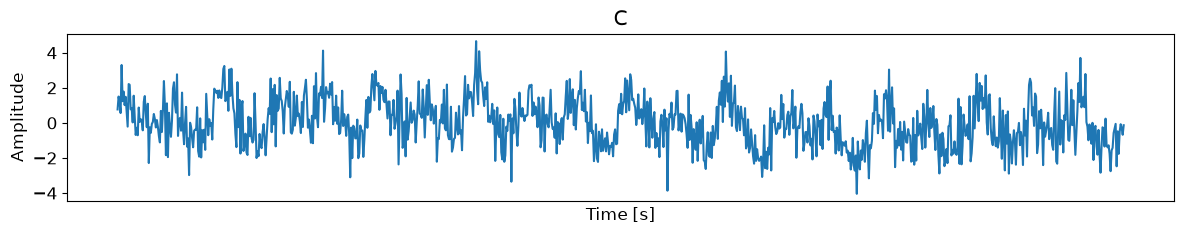

In [52]:
# C

t_eeg = np.arange(0, duration, 1/sampling_frequency)

# oscylacje
theta = 0.7 * np.sin(2 * np.pi * 6 * t_eeg)
alpha = 1.0 * np.sin(2 * np.pi * 10 * t_eeg + 0.5)
beta  = 0.3 * np.sin(2 * np.pi * 20 * t_eeg)

# dryft
drift = 0.5 * np.sin(2 * np.pi * 0.5 * t_eeg)

# szum
noise = rng.normal(0, 1.0, len(t_eeg))

eeg_like = theta + alpha + beta + drift + noise

plt.figure(figsize=(12, 2.5))
plt.plot(t_eeg, eeg_like)

plt.title("C")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.tight_layout()
plt.show()

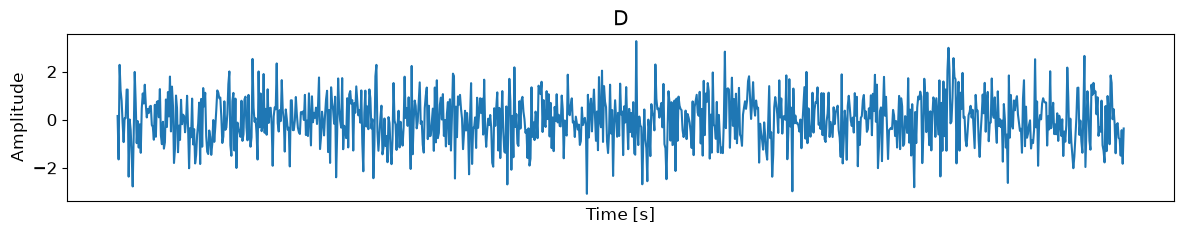

In [31]:
# D
t_noise = np.arange(0, duration, 1/sampling_frequency)

white_noise = rng.normal(
    loc=0,
    scale=1,
    size=len(t_noise)
)

plt.figure(figsize=(12, 2.5))
plt.plot(t_noise, white_noise)

plt.title("D")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.tight_layout()
plt.show()

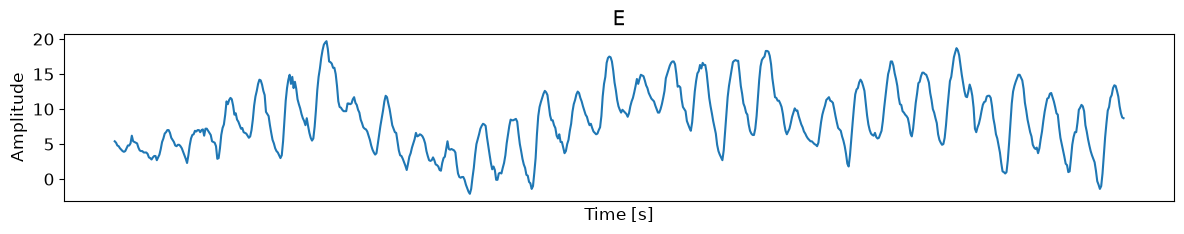

In [54]:
# E
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 50.0647,
    "longitude": 19.9450,
    "start_date": "2026-03-30",
    "end_date": "2026-04-30",
    "hourly": "temperature_2m",
    "timezone": "Europe/Warsaw"
}

response = requests.get(url, params=params)
response.raise_for_status()

weather = response.json()

df_temp = pd.DataFrame({
    "time": pd.to_datetime(weather["hourly"]["time"]),
    "temperature": weather["hourly"]["temperature_2m"]
})

#df_temp.head()

plt.figure(figsize=(12, 2.5))

plt.plot(df_temp["time"], df_temp["temperature"])

plt.title("E")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.tight_layout()
plt.show()

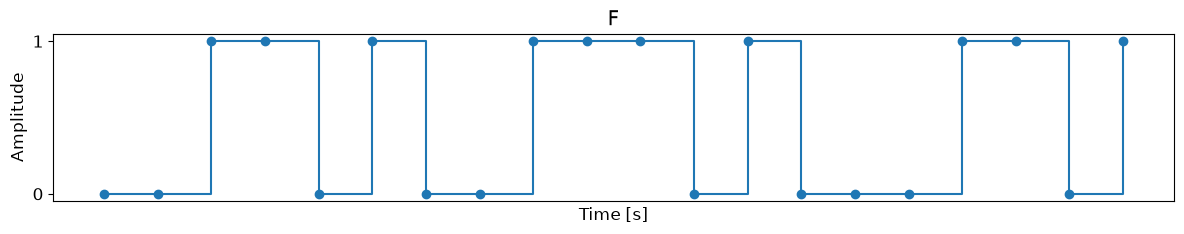

In [55]:
# F
t_digital = np.arange(20)

digital = np.array([
    0, 0, 1, 1, 0,
    1, 0, 0, 1, 1,
    1, 0, 1, 0, 0,
    0, 1, 1, 0, 1
])

plt.figure(figsize=(12, 2.5))

plt.step(t_digital, digital, where="post")
plt.scatter(t_digital, digital)

plt.title("F")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.yticks([0, 1])

plt.tight_layout()
plt.show()

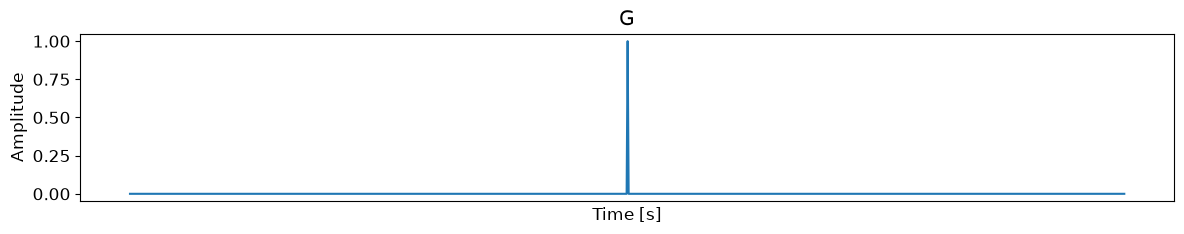

In [56]:
# G
t_event = np.arange(0, 2, 1/sampling_frequency)

event = np.zeros_like(t_event)

event[np.argmin(np.abs(t_event - 1.0))] = 1

plt.figure(figsize=(12, 2.5))

plt.plot(t_event, event)

plt.title("G")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.tight_layout()
plt.show()

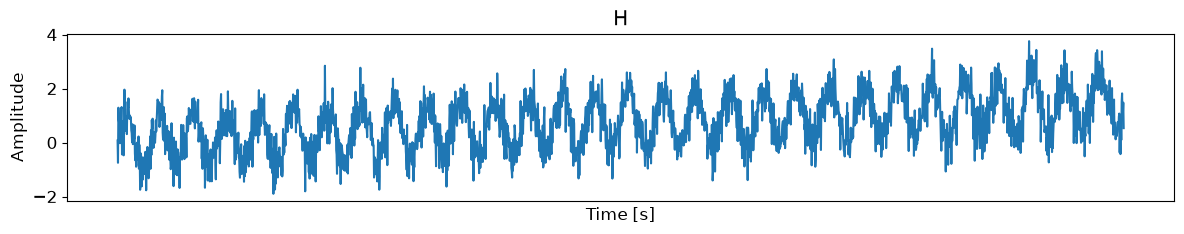

In [57]:
# H

sampling_frequency = 250
duration = 10

t_mix = np.arange(0, duration, 1/sampling_frequency)

slow_trend = 0.15 * t_mix
oscillation = np.sin(2 * np.pi * 3 * t_mix)
noise = rng.normal(0, 0.5, len(t_mix))

mixed_signal = slow_trend + oscillation + noise

plt.figure(figsize=(12, 2.5))

plt.plot(t_mix, mixed_signal)

plt.title("H")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.xticks([])

plt.tight_layout()
plt.show()

In [58]:
plots_reveal = True

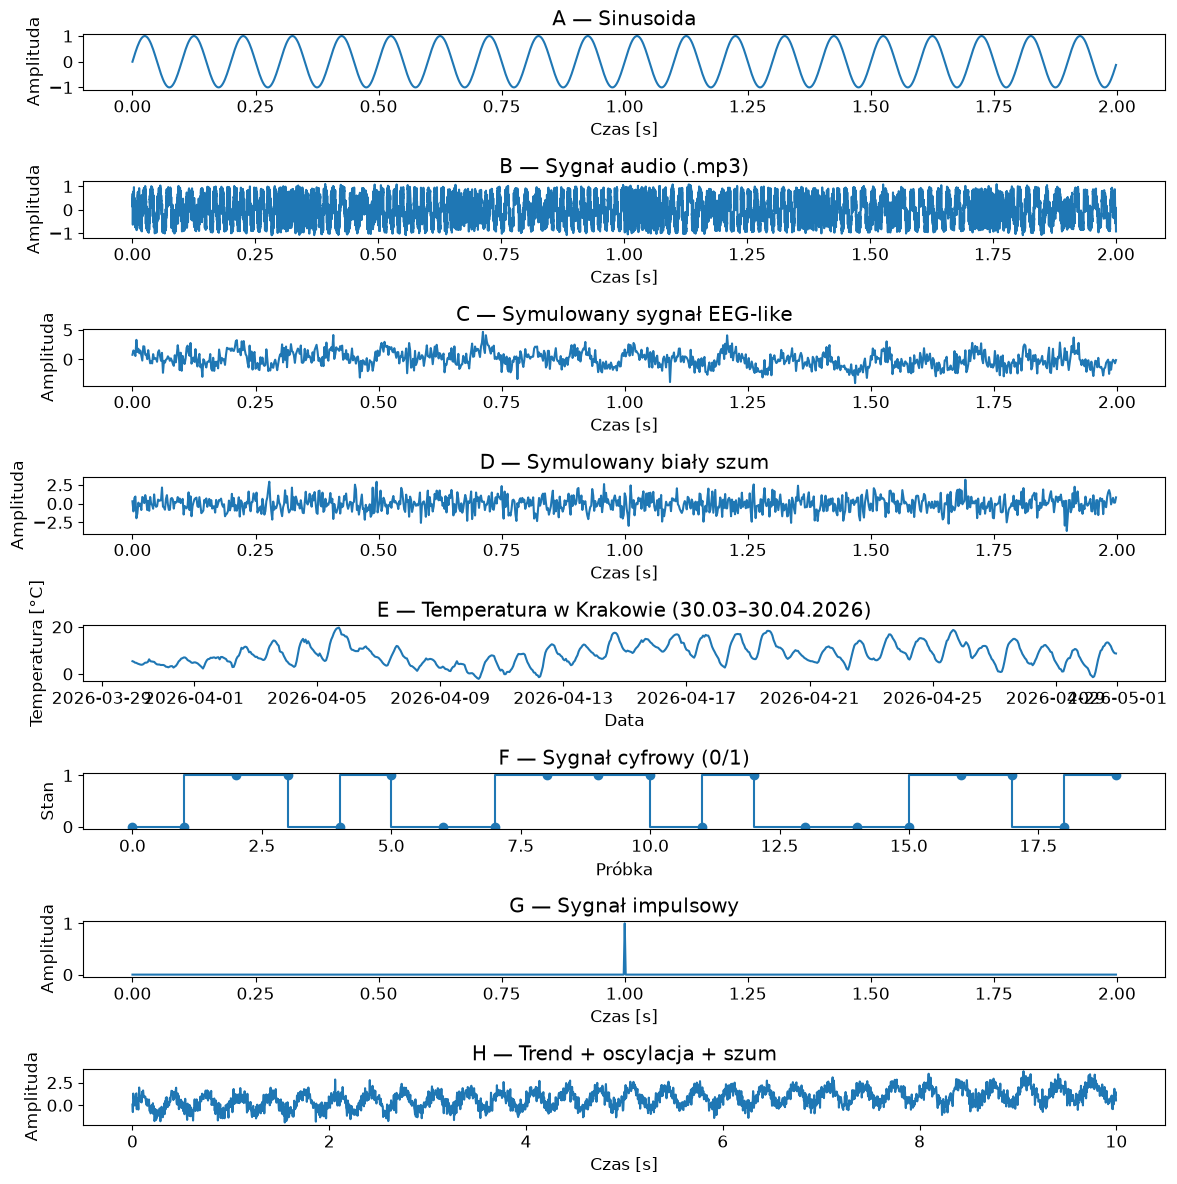

In [59]:
fig, axes = plt.subplots(8, 1, figsize=(12, 12))

# A
axes[0].plot(t, A)

# B
axes[1].plot(t_music, music)

# C
axes[2].plot(t_eeg, eeg_like)

# D
axes[3].plot(t_noise, white_noise)

# E
axes[4].plot(df_temp["time"], df_temp["temperature"])

# F
axes[5].step(t_digital, digital, marker="o")

# G
axes[6].plot(t_event, event)

# H
axes[7].plot(t_mix, mixed_signal)

if plots_reveal:

    titles = [
        "A — Sinusoida",
        "B — Sygnał audio (.mp3)",
        "C — Symulowany sygnał EEG-like",
        "D — Symulowany biały szum",
        "E — Temperatura w Krakowie (30.03–30.04.2026)",
        "F — Sygnał cyfrowy (0/1)",
        "G — Sygnał impulsowy",
        "H — Trend + oscylacja + szum"
    ]

    ylabels = [
        "Amplituda",
        "Amplituda",
        "Amplituda",
        "Amplituda",
        "Temperatura [°C]",
        "Stan",
        "Amplituda",
        "Amplituda"
    ]

    xlabels = [
        "Czas [s]",
        "Czas [s]",
        "Czas [s]",
        "Czas [s]",
        "Data",
        "Próbka",
        "Czas [s]",
        "Czas [s]"
    ]

    for ax, title, ylabel, xlabel in zip(
        axes,
        titles,
        ylabels,
        xlabels
    ):
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.set_xlabel(xlabel)

else:

    for i, ax in enumerate(axes):

        ax.set_title(chr(65 + i))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")


plt.tight_layout()
plt.show()

# Terminy, które będą się powtarzać

## Krótkie przypomnienie z tryg****etrii

Sinusoidę możemy opisać jako:

$$x(t) = A\sin(2\pi f t + \varphi)$$

gdzie:

- $A$ — **amplituda**
- $f$ — **częstotliwość** [Hz]
- $t$ — **czas** [s]
- $\varphi$ — **faza**

### Okres i częstotliwość

**Okres $T$** mówi, ile czasu trwa jeden pełny cykl.

**Częstotliwość $f$** mówi, ile pełnych cykli występuje w ciągu jednej sekundy.

$$f = \frac{1}{T}$$
$$T = \frac{1}{f}$$

Jednostką częstotliwości jest **herc (Hz)**:

$$1\ \mathrm{Hz} = 1\ \text{cykl/s}$$

Przykładowo:

- $1$ Hz → 1 cykl na sekundę → $T = 1$ s
- $2$ Hz → 2 cykle na sekundę → $T = 0.5$ s
- $10$ Hz → 10 cykli na sekundę → $T = 0.1$ s
- $20$ Hz → 20 cykli na sekundę → $T = 0.05$ s


### Faza

Częstotliwość mówi nam, **"jak szybko powtarza się cykl"**.

Faza mówi nam, **"w którym miejscu cyklu jesteśmy"**.

Sinusoidę możemy zapisać jako:


Fazę możemy wyrażać w **stopniach** lub **radianach**:


$$360^\circ = 2\pi$$
$$180^\circ = \pi$$
$$90^\circ = \frac{\pi}{2}$$

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def pokaz_sinus(kat=0):

    # stopnie -> radiany
    theta = np.deg2rad(kat)

    # koło jednostkowe
    angle_circle = np.linspace(0, 2*np.pi, 500)
    x_circle = np.cos(angle_circle)
    y_circle = np.sin(angle_circle)

    # sinusoida
    angle_wave = np.linspace(0, 2*np.pi, 500)
    sine_wave = np.sin(angle_wave)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4)
    )

    # ==========================================
    # KOŁO JEDNOSTKOWE
    # ==========================================

    axes[0].plot(x_circle, y_circle)

    # promień
    axes[0].plot(
        [0, np.cos(theta)],
        [0, np.sin(theta)]
    )

    # punkt na okręgu
    axes[0].scatter(
        np.cos(theta),
        np.sin(theta),
        s=80
    )

    # wysokość = sin(theta)
    axes[0].plot(
        [np.cos(theta), np.cos(theta)],
        [0, np.sin(theta)],
        linestyle="--"
    )

    axes[0].axhline(0, linewidth=0.8)
    axes[0].axvline(0, linewidth=0.8)

    axes[0].set_xlim(-1.2, 1.2)
    axes[0].set_ylim(-1.2, 1.2)
    axes[0].set_aspect("equal")

    axes[0].set_title(
        f"Kąt = {kat}°   |   sin(θ) = {np.sin(theta):.2f}"
    )

    axes[0].set_xlabel("cos(θ)")
    axes[0].set_ylabel("sin(θ)")


    # ==========================================
    # SINUSOIDA
    # ==========================================

    axes[1].plot(
        np.rad2deg(angle_wave),
        sine_wave
    )

    # aktualny punkt
    axes[1].scatter(
        kat,
        np.sin(theta),
        s=80
    )

    axes[1].axhline(0, linewidth=0.8)

    axes[1].set_xlim(0, 360)
    axes[1].set_ylim(-1.2, 1.2)

    axes[1].set_xticks(
        [0, 90, 180, 270, 360]
    )

    axes[1].set_xlabel("Kąt [°]")
    axes[1].set_ylabel("sin(θ)")
    axes[1].set_title("Sinusoida")

    plt.tight_layout()
    plt.show()


slider = widgets.IntSlider(
    value=0,
    min=0,
    max=360,
    step=1,
    description="Kąt:"
)

widgets.interactive(
    pokaz_sinus,
    kat=slider
)

interactive(children=(IntSlider(value=0, description='Kąt:', max=360), Output()), _dom_classes=('widget-intera…

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def pokaz_sinusoide(amplituda=1.0, czestotliwosc=2.0, faza=0):

    # Parametry techniczne
    sampling_frequency = 500
    duration = 1

    t = np.arange(
        0,
        duration,
        1 / sampling_frequency
    )

    # Faza: stopnie -> radiany
    faza_rad = np.deg2rad(faza)

    # Sinusoida
    signal = amplituda * np.sin(
        2 * np.pi * czestotliwosc * t + faza_rad
    )

    # Wykres
    plt.figure(figsize=(12, 4))

    plt.plot(
        t,
        signal,
        linewidth=2
    )

    plt.axhline(
        0,
        linewidth=0.8
    )

    plt.xlabel("Czas [s]")
    plt.ylabel("Amplituda")

    plt.ylim(-3.2, 3.2)
    plt.xlim(0, duration)

    plt.title(
        f"A = {amplituda:.1f}   |   "
        f"f = {czestotliwosc:.1f} Hz   |   "
        f"φ = {faza}°"
    )

    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


# ============================================================
# SUWAKI
# ============================================================

slider_amplituda = widgets.FloatSlider(
    value=1.0,
    min=0.1,
    max=3.0,
    step=0.1,
    description="Amplituda:",
    continuous_update=True
)

slider_czestotliwosc = widgets.FloatSlider(
    value=2.0,
    min=0.5,
    max=10.0,
    step=0.5,
    description="Częstotliwość:",
    continuous_update=True
)

slider_faza = widgets.IntSlider(
    value=0,
    min=0,
    max=360,
    step=10,
    description="Faza:",
    continuous_update=True
)


# ============================================================
# INTERAKTYWNY WYKRES
# ============================================================

widgets.interactive(
    pokaz_sinusoide,
    amplituda=slider_amplituda,
    czestotliwosc=slider_czestotliwosc,
    faza=slider_faza
)

interactive(children=(FloatSlider(value=1.0, description='Amplituda:', max=3.0, min=0.1), FloatSlider(value=2.…

# $$x(t) = A\sin(2\pi f t + \varphi)$$

gdzie:

- $A$ — **amplituda**
- $f$ — **częstotliwość** [Hz]
- $t$ — **czas** [s]
- $\varphi$ — **faza**


In [104]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


# ============================================================
# PARAMETRY CZASU
# ============================================================

sampling_frequency = 500
duration = 2

t = np.arange(
    0,
    duration,
    1 / sampling_frequency
)


# ============================================================
# SZUM EEG-LIKE
# generowany tylko raz
# ============================================================

rng = np.random.default_rng(42)

white_noise = rng.normal(
    0,
    1,
    len(t)
)

kernel = np.ones(15) / 15

eeg_noise = np.convolve(
    white_noise,
    kernel,
    mode="same"
)

eeg_noise = eeg_noise / np.std(eeg_noise)


# ============================================================
# FUNKCJA RYSUJĄCA
# ============================================================

def pokaz_sinusoidy(
    pokaz_1=True, A1=1.0, f1=2.0, faza1=0,
    pokaz_2=True, A2=1.0, f2=2.0, faza2=0,
    pokaz_3=True, A3=1.0, f3=2.0, faza3=0,
    pokaz_sume=False,
    dodaj_szum=False,
    amplituda_szumu=0.5
):

    # ============================================================
    # SYGNAŁY
    # ============================================================

    signal_1 = A1 * np.sin(
        2 * np.pi * f1 * t + np.deg2rad(faza1)
    )

    signal_2 = A2 * np.sin(
        2 * np.pi * f2 * t + np.deg2rad(faza2)
    )

    signal_3 = A3 * np.sin(
        2 * np.pi * f3 * t + np.deg2rad(faza3)
    )


    # ============================================================
    # SUMA
    # ============================================================

    suma = np.zeros_like(t)

    if pokaz_1:
        suma += signal_1

    if pokaz_2:
        suma += signal_2

    if pokaz_3:
        suma += signal_3

    if dodaj_szum:
        suma += amplituda_szumu * eeg_noise


    # ============================================================
    # LICZBA WYKRESÓW
    # ============================================================

    if pokaz_sume:
        fig, axes = plt.subplots(
            2, 1,
            figsize=(12, 7),
            sharex=True
        )

        ax_top = axes[0]
        ax_bottom = axes[1]

    else:
        fig, ax_top = plt.subplots(
            1, 1,
            figsize=(12, 4)
        )


    # ============================================================
    # GÓRNY WYKRES — KOMPONENTY
    # ============================================================

    if pokaz_1:
        ax_top.plot(
            t,
            signal_1,
            linewidth=2,
            label=f"1: A={A1:.1f}, f={f1:.1f} Hz, φ={faza1}°"
        )

    if pokaz_2:
        ax_top.plot(
            t,
            signal_2,
            linewidth=2,
            label=f"2: A={A2:.1f}, f={f2:.1f} Hz, φ={faza2}°"
        )

    if pokaz_3:
        ax_top.plot(
            t,
            signal_3,
            linewidth=2,
            label=f"3: A={A3:.1f}, f={f3:.1f} Hz, φ={faza3}°"
        )

    ax_top.axhline(
        0,
        linewidth=0.8
    )

    ax_top.set_xlim(0, duration)
    ax_top.set_ylim(-3.2, 3.2)

    ax_top.set_ylabel("Amplituda")

    ax_top.set_title(
        r"$x(t)=A\sin(2\pi ft+\varphi)$"
    )

    ax_top.grid(alpha=0.2)

    if pokaz_1 or pokaz_2 or pokaz_3:
        ax_top.legend(
            loc="upper right"
        )

    if not pokaz_sume:
        ax_top.set_xlabel("Czas [s]")


    # ============================================================
    # DOLNY WYKRES — POJAWIA SIĘ TYLKO PO ZAZNACZENIU
    # ============================================================

    if pokaz_sume:

        ax_bottom.plot(
            t,
            suma,
            linewidth=1.5
        )

        ax_bottom.axhline(
            0,
            linewidth=0.8
        )

        ax_bottom.set_xlim(0, duration)
        ax_bottom.set_ylim(-6, 6)

        ax_bottom.set_xlabel("Czas [s]")
        ax_bottom.set_ylabel("Amplituda")

        if dodaj_szum:
            ax_bottom.set_title(
                "Suma sygnałów + szum EEG-like"
            )
        else:
            ax_bottom.set_title(
                "Suma sygnałów"
            )

        ax_bottom.grid(alpha=0.2)


    plt.tight_layout()
    plt.show()


# ============================================================
# FUNKCJA TWORZĄCA SUWAKI
# ============================================================

def suwaki():

    return {

        "A": widgets.FloatSlider(
            value=1.0,
            min=0.1,
            max=3.0,
            step=0.1,
            description="A:"
        ),

        "f": widgets.FloatSlider(
            value=2.0,
            min=0.5,
            max=20.0,
            step=0.5,
            description="f [Hz]:"
        ),

        "faza": widgets.IntSlider(
            value=0,
            min=0,
            max=360,
            step=10,
            description="φ [°]:"
        )
    }


# ============================================================
# TRZY IDENTYCZNE SYGNAŁY NA POCZĄTKU
# ============================================================

s1 = suwaki()
s2 = suwaki()
s3 = suwaki()


pokaz_1 = widgets.Checkbox(
    value=True,
    description="Pokaż sygnał 1"
)

pokaz_2 = widgets.Checkbox(
    value=True,
    description="Pokaż sygnał 2"
)

pokaz_3 = widgets.Checkbox(
    value=True,
    description="Pokaż sygnał 3"
)


# ============================================================
# KONTROLKI DOLNEGO WYKRESU
# ============================================================

pokaz_sume = widgets.Checkbox(
    value=False,
    description="Pokaż sumę"
)

dodaj_szum = widgets.Checkbox(
    value=False,
    description="Dodaj szum EEG-like"
)

amplituda_szumu = widgets.FloatSlider(
    value=0.5,
    min=0,
    max=3,
    step=0.1,
    description="Szum:"
)


# ============================================================
# UKŁAD KONTROLEK
# ============================================================

kontrolki_sygnalow = widgets.HBox([

    widgets.VBox([
        widgets.HTML("<b>Sygnał 1</b>"),
        pokaz_1,
        s1["A"],
        s1["f"],
        s1["faza"]
    ]),

    widgets.VBox([
        widgets.HTML("<b>Sygnał 2</b>"),
        pokaz_2,
        s2["A"],
        s2["f"],
        s2["faza"]
    ]),

    widgets.VBox([
        widgets.HTML("<b>Sygnał 3</b>"),
        pokaz_3,
        s3["A"],
        s3["f"],
        s3["faza"]
    ])
])


kontrolki_sumy = widgets.HBox([
    pokaz_sume,
    dodaj_szum,
    amplituda_szumu
])


# ============================================================
# POŁĄCZENIE KONTROLEK Z WYKRESEM
# ============================================================

output = widgets.interactive_output(

    pokaz_sinusoidy,

    {
        "pokaz_1": pokaz_1,
        "A1": s1["A"],
        "f1": s1["f"],
        "faza1": s1["faza"],

        "pokaz_2": pokaz_2,
        "A2": s2["A"],
        "f2": s2["f"],
        "faza2": s2["faza"],

        "pokaz_3": pokaz_3,
        "A3": s3["A"],
        "f3": s3["f"],
        "faza3": s3["faza"],

        "pokaz_sume": pokaz_sume,
        "dodaj_szum": dodaj_szum,
        "amplituda_szumu": amplituda_szumu
    }
)


display(
    kontrolki_sygnalow,
    kontrolki_sumy,
    output
)

Output()

# Nasza percepcja vs dane

In [103]:
duration = 2
sampling_frequency = 100

t = np.arange(0, duration, 1/sampling_frequency)
A = np.sin(2 * np.pi * 2 * t)

zoom_params = (0, 0.5)

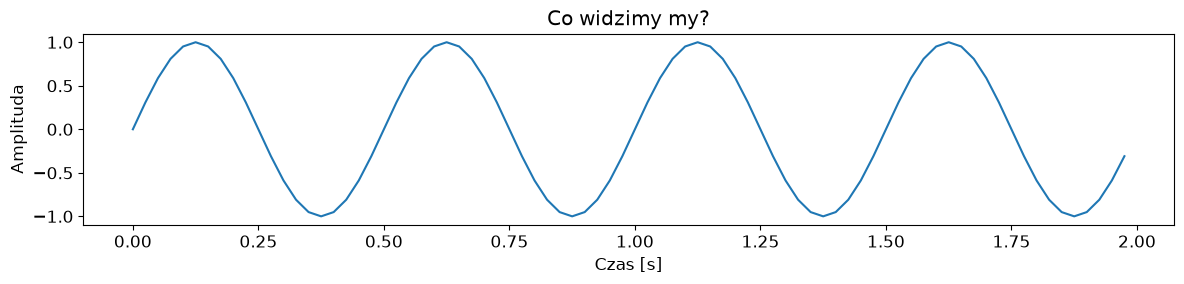

In [95]:
plt.figure(figsize=(12, 3))

plt.plot(t, A)

plt.xlabel("Czas [s]")
plt.ylabel("Amplituda")
plt.title("Co widzimy my?")

plt.tight_layout()
plt.show()

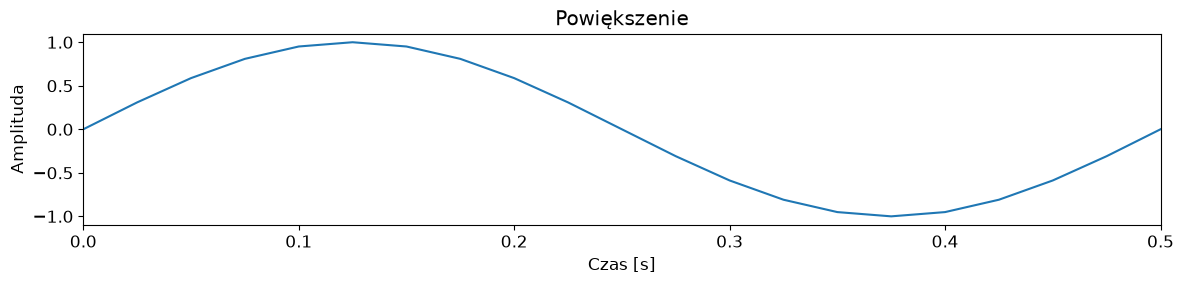

In [96]:
plt.figure(figsize=(12, 3))

plt.plot(t, A)

plt.xlim(zoom_params)

plt.xlabel("Czas [s]")
plt.ylabel("Amplituda")
plt.title("Powiększenie")

plt.tight_layout()
plt.show()

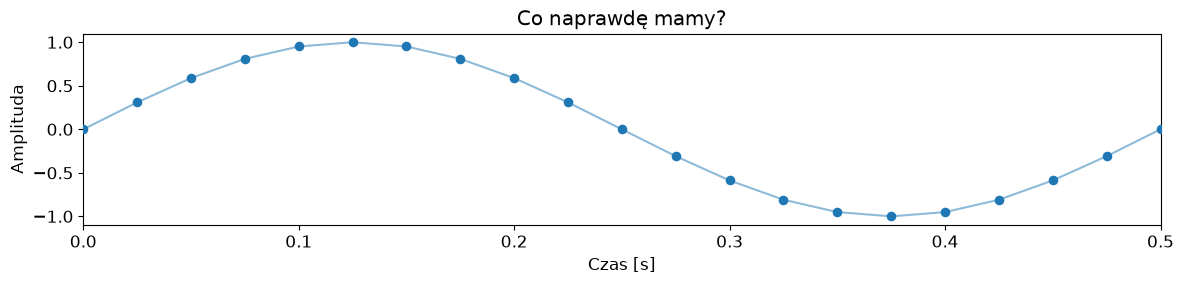

In [97]:
plt.figure(figsize=(12, 3))

plt.plot(t, A, alpha=0.5)

# Rzeczywiste próbki
plt.scatter(t, A, s=35, zorder=3)

plt.xlim(zoom_params)

plt.xlabel("Czas [s]")
plt.ylabel("Amplituda")
plt.title("Co naprawdę mamy?")

plt.tight_layout()
plt.show()

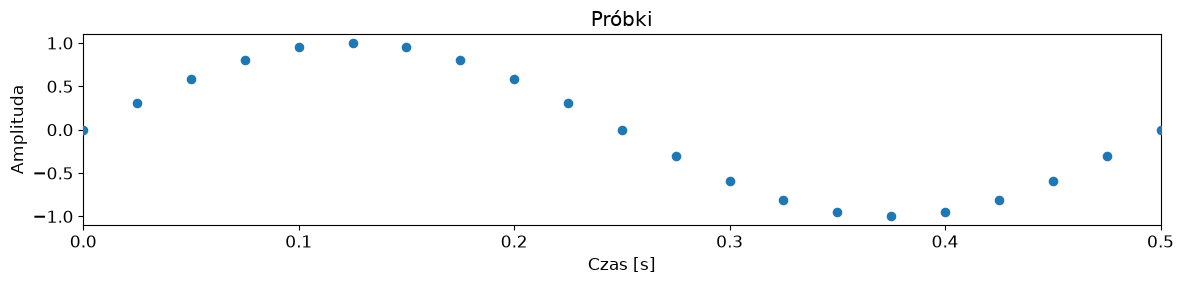

In [98]:
plt.figure(figsize=(12, 3))

plt.scatter(t, A, s=35, zorder=3)

plt.xlim(zoom_params)

plt.xlabel("Czas [s]")
plt.ylabel("Amplituda")
plt.title("Próbki")

plt.tight_layout()
plt.show()

### Częstotliwość
**To liczba cykli zjawiska okresowego w jednostce czasu**

$$f = \frac{1}{T}$$

gdzie:

- $f$ — częstotliwość,
- $T$ — odstęp czasu pomiędzy kolejnymi cyklami.

### Częstotliwość próbkowania [Hz]

Częstotliwość próbkowania mówi nam, **ile razy w ciągu jednej sekundy mierzymy wartość sygnału**.

$$f_s = \frac{1}{\Delta t}$$

gdzie:

- $f_s$ — częstotliwość próbkowania,
- $\Delta t$ — odstęp czasu pomiędzy kolejnymi próbkami.

## Każda próbka opisuje:

- **moment pomiaru**                    - oś x (Czas [s])
- **wartość sygnału w tym momencie**    - oś y (Amplituda)

Możemy więc myśleć o niej jako o parze:

$$(t_i,\ x_i)$$

## Co widzi Python?

Na wykresie widzimy kształt sygnału.

Ale co tak naprawdę znajduje się w pamięci komputera?

In [99]:
print(A[:20])

[ 0.00000000e+00  3.09016994e-01  5.87785252e-01  8.09016994e-01
  9.51056516e-01  1.00000000e+00  9.51056516e-01  8.09016994e-01
  5.87785252e-01  3.09016994e-01  1.22464680e-16 -3.09016994e-01
 -5.87785252e-01 -8.09016994e-01 -9.51056516e-01 -1.00000000e+00
 -9.51056516e-01 -8.09016994e-01 -5.87785252e-01 -3.09016994e-01]


In [100]:
print("Typ danych: ", type(A))
print("Shape tablicy: ", A.shape)

Typ danych:  <class 'numpy.ndarray'>
Shape tablicy:  (80,)


In [102]:
print("Wartości sygnału: ", A[:10])
print("Czas: ", t[:10])
print("\n")
for czas, wartosc in zip(t[:10], A[:10]):
    print(f"{czas:.4f} s  →  {wartosc:.4f}")

Wartości sygnału:  [0.         0.30901699 0.58778525 0.80901699 0.95105652 1.
 0.95105652 0.80901699 0.58778525 0.30901699]
Czas:  [0.    0.025 0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225]


0.0000 s  →  0.0000
0.0250 s  →  0.3090
0.0500 s  →  0.5878
0.0750 s  →  0.8090
0.1000 s  →  0.9511
0.1250 s  →  1.0000
0.1500 s  →  0.9511
0.1750 s  →  0.8090
0.2000 s  →  0.5878
0.2250 s  →  0.3090
